# Aperture toy ring

We will build a compact six-arc toy ring for demonstrating `xtrack.aperture`.

The machine is intentionally simple optically and interesting geometrically:

- six 60 degree arcs built from FODO cells and dipoles;
- one four-bend chicane;
- one large aggregate pipe installed from `chicane.start`, so the aperture
  model does not simply follow every survey element in the chicane;
- curved arc-bend pipes, octagonal quadrupole pipes, racetrack RF pipes,
  rectellipse detector transitions, and one polygon septum transition;
- a deliberately tight detector neck that should give a visible N1 bottleneck.

In this section we will start by building the lattice.

In [1]:
import xtrack as xt
import numpy as np
import logging
import warnings

# Silence annoying but harmless warnings from matplotlib
logging.getLogger("matplotlib").setLevel(logging.ERROR)
warnings.filterwarnings('ignore', message='.*No artists with labels found.*')

In [2]:
env = xt.Environment()
env.particle_ref = xt.Particles(p0c=5e9, mass0=xt.PROTON_MASS_EV)
env.vars.default_to_zero = True

n_arcs = 6
cells_per_arc = 2
bends_per_cell = 2
n_arc_bends = n_arcs * cells_per_arc * bends_per_cell

env["l_mb"] = 1.20  # length of the main bends
env["l_mq"] = 0.32  # length of the quadrupoles
env["l_chicane_bend"] = 0.55  # length of the chicane bends
env["ang_mb"] = 2 * np.pi / n_arc_bends  # angle of the main bends
env["ang_chicane"] = -np.deg2rad(9.0)  # angle of the chicane bends

env.new("mb", xt.RBend, length_straight="l_mb", angle="ang_mb")
env.new("mq", xt.Quadrupole, length="l_mq")
env.new("qf", "mq", k1="kqf")
env.new("qd", "mq", k1="kqd")

cell = env.new_line(
    name="arc_cell",
    length=4.80,
    components=[
        env.place("qf", at=0.35),
        env.place("mb", at=1.35),
        env.place("qd", at=2.40),
        env.place("mb", at=3.45),
    ],
)
arc = cell + cell

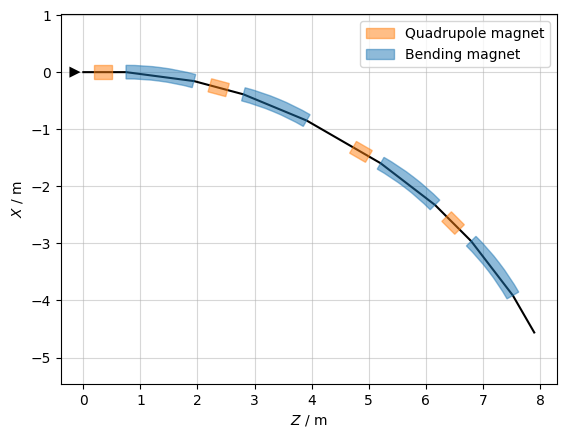

In [3]:
arc.survey().plot()

In [4]:
env.new("bc_p", xt.RBend, length_straight="l_chicane_bend", angle="ang_chicane")
env.new("bc_m", xt.RBend, length_straight="l_chicane_bend", angle="-ang_chicane")

chicane = env.new_line(
    name="chicane",
    length=7.80,
    components=[
        env.new("chicane.start", xt.Marker, at=0.00),
        env.place("bc_p", at=0.80),
        env.place("bc_m", at=2.15),
        env.new("ip", xt.Marker, at=3.90),
        env.place("bc_m", at=5.65),
        env.place("bc_p", at=7.00),
        env.new("chicane.end", xt.Marker, at=7.80),
    ],
)

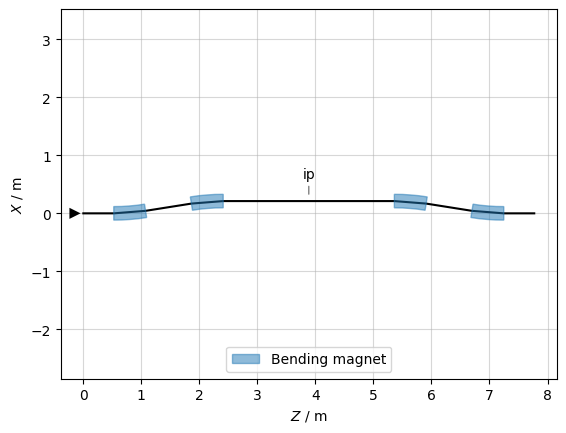

In [5]:
chicane_survey = chicane.survey()
chicane_survey.plot(labels=['ip'])

In [6]:
sector_straight_length = float(chicane_survey.Z[-1] - chicane_survey.Z[0])

env.new("rf", xt.Cavity, voltage=0.0, frequency=400e6)

utility_straight = env.new_line(
    name="utility_straight",
    length=sector_straight_length,
    components=[
        env.new("utility.mid", xt.Marker, at=sector_straight_length / 2),
        env.place("rf", at=2.45),
    ],
)

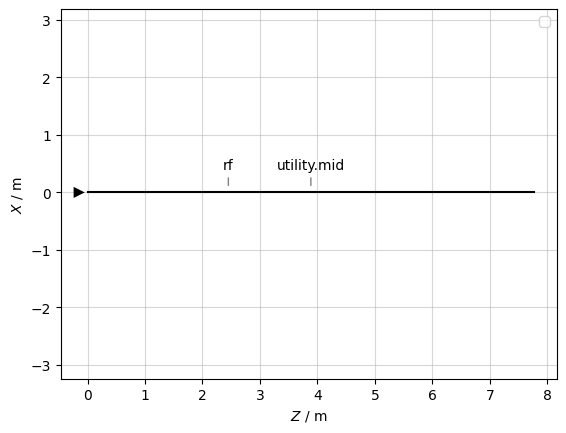

In [7]:
utility_straight.survey().plot(labels=['utility.mid', 'rf'])

In [8]:
short_straight = env.new_line(
    name="short_straight",
    length=sector_straight_length,
    components=[
        env.new("short.mid", xt.Marker, at=sector_straight_length / 2)
    ],
)

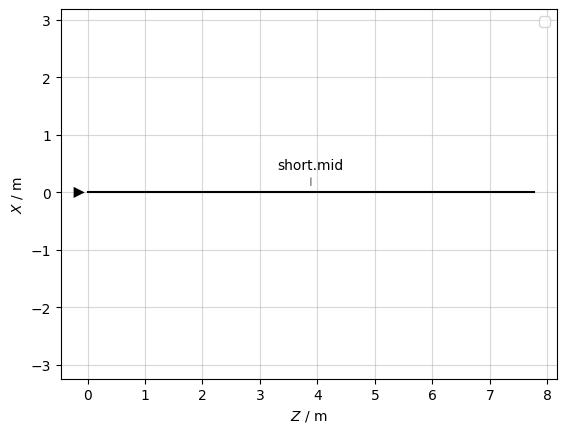

In [9]:
short_straight.survey().plot(labels='short.mid')

In [10]:
ring = (
    chicane
    + arc
    + short_straight
    + arc
    + utility_straight
    + arc
    + short_straight
    + arc
    + utility_straight
    + arc
    + short_straight
    + arc
)
ring.replace_all_repeated_elements()

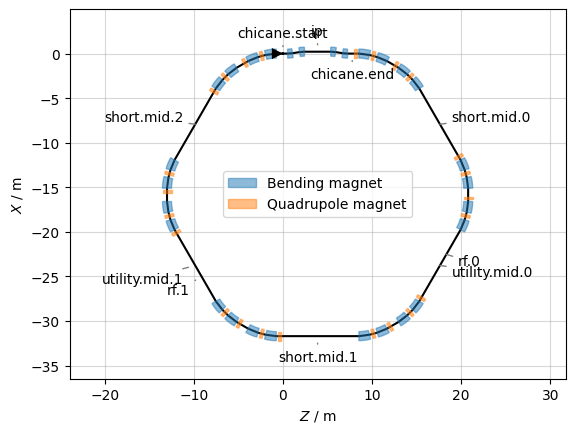

In [11]:
ring.survey().plot(labels=['ip', 'chicane.*', 'rf.*', 'utility.mid.*', 'short.mid.*'])

In [12]:
ring.particle_ref = env.particle_ref
ring.twiss_default["method"] = "4d"

env.vars.update(
    {
        "kqf": 0.38,
        "kqd": -0.42,
    }
)
env.vars.default_to_zero = False
env["ring"] = ring

In [13]:
ring.get_table().rows[r'^[^\|].*']

LineTable: 63 rows, 13 cols
name                      s element_type isthick isreplica parent_name parent_type prototype ...
chicane.start             0 Marker         False     False None        None        None     
bc_p.0             0.524717 RBend           True     False None        None        bc_p     
bc_m.0              1.87472 RBend           True     False None        None        bc_m     
ip                      3.9 Marker         False     False None        None        None     
bc_m.1              5.37472 RBend           True     False None        None        bc_m     
bc_p.1              6.72472 RBend           True     False None        None        bc_p     
chicane.end             7.8 Marker         False     False None        None        None     
qf.0                   7.99 Quadrupole      True     False None        None        qf       
mb.0                8.54828 RBend           True     False None        None        mb       
qd.0                  10.04 Quadrupole

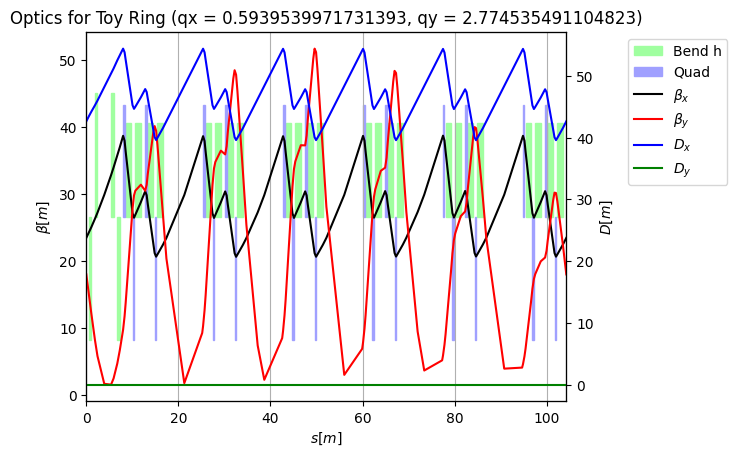

In [14]:
tw = ring.twiss()

import matplotlib.pyplot as plt
tw.plot()
plt.title(f'Optics for Toy Ring (qx = {tw.qx}, qy = {tw.qy})')
plt.show()

In [15]:
env.to_json('toy_ring.json')